# Evaluación ampliada y robustez

Un empate en Telco puede esconder dos historias distintas: un modelo frágil que tuvo un buen día, o uno estable que
simplemente no tiene nada que ganarle a este conjunto. Para distinguirlas repetimos el procedimiento completo en tres
conjuntos de churn de otra procedencia y sometimos el modelo a los estudios de robustez del protocolo.

Todos los estudios de este capítulo son exploratorios, salvo los conjuntos adicionales y la prueba entre conjuntos, que
forman parte de la familia confirmatoria. Los de robustez usan los 5 pliegues externos de la repetición 0 de Telco y los
hiperparámetros que eligió la validación anidada, sin volver a optimizar. Las perturbaciones se aplican solo al pliegue
de ajuste: el de evaluación queda limpio.

In [1]:
# Configuración: solo se leen tablas versionadas (experiments/resultados/tablas y tablas/libro)
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from src.presentacion import tabla, nota, estilo_figuras, numero, valor_p, NOMBRES, CONJUNTOS, AZUL, RIESGO, ACENTO, GRIS
estilo_figuras()
TAB = ROOT / "experiments" / "resultados" / "tablas"; LIB = TAB / "libro"
FAM = pd.read_csv(TAB / "familia_resultados.csv")
RESUMEN = pd.read_csv(TAB / "resumen_modelos.csv")
POR_PLIEGUE = pd.read_csv(TAB / "metricas_por_pliegue.csv")
ROB = pd.read_csv(LIB / "robustez_resumen.csv")
VEREDICTO = json.loads((TAB / "veredicto_R3.json").read_text(encoding="utf-8"))
MEJOR = VEREDICTO["mejor_benchmark"]["telco"]
BASE0 = POR_PLIEGUE[(POR_PLIEGUE.conjunto == "telco") & (POR_PLIEGUE.rep == 0)]   # validación anidada, repetición 0
FOCO = ["RegionalMAPEM", MEJOR, "mapem_K1", "stacking_logistico", "hist_gb", "catboost"]

## Conjuntos de datos adicionales

Elegimos los tres conjuntos antes de ver cómo rendía el modelo en ellos, con un criterio fijado en el protocolo: churn de
telecomunicaciones de fuente pública, con licencia que permita su uso y que se diferencien de Telco en tamaño, dimensión,
desbalance o procedencia.

In [2]:
# Descripción de los cuatro conjuntos (calculada con los mismos cargadores de la validación anidada)
C = pd.read_csv(LIB / "conjuntos.csv")
fuente = {"telco": "IBM, versión de Kaggle; solo desarrollo", "uci_563_iranian": "UCI 563, CC BY 4.0; sin las 300 filas duplicadas",
          "openml_40701_churn": "OpenML 40701; sin el identificador phone_number", "openml_1112_kddcup09_churn": "OpenML 1112 (Orange); submuestra estratificada fija"}
rasgo = {"telco": "Contratos y servicios de clientes residenciales", "uci_563_iranian": "Agregados de uso de 9 meses, otro país y operador",
         "openml_40701_churn": "Uso por franja horaria y llamadas al servicio", "openml_1112_kddcup09_churn": "Alta dimensión, variables anónimas, muchos faltantes"}
tabla(pd.DataFrame({"Conjunto": C.conjunto.map(CONJUNTOS), "Fuente": C.conjunto.map(fuente), "Clientes": C.n,
                    "Variables": C.p_original, "Columnas tras preprocesar": C.p_preprocesado, "% churn": 100 * C.churn,
                    "% celdas faltantes": 100 * C.celdas_faltantes, "Pliegues externos": C.pliegues_externos,
                    "Rasgo distintivo": C.conjunto.map(rasgo)}),
      "Tabla 7.1. Conjuntos de datos de la evaluación", decimales=1, buscar=False,
      nota="KDDCup09 usa 2 repeticiones de 5 pliegues, decididas por costo de cómputo antes de ver resultados.")

Conjunto,Fuente,Clientes,Variables,Columnas tras preprocesar,% churn,% celdas faltantes,Pliegues externos,Rasgo distintivo
Telco,"IBM, versión de Kaggle; solo desarrollo",5.634,19,24,"26,5","0,0",25,Contratos y servicios de clientes residenciales
Iranian (UCI 563),"UCI 563, CC BY 4.0; sin las 300 filas duplicadas",2.850,13,13,"15,6","0,0",25,"Agregados de uso de 9 meses, otro país y operador"
Churn (OpenML 40701),OpenML 40701; sin el identificador phone_number,5.000,19,70,"14,1","0,0",25,Uso por franja horaria y llamadas al servicio
KDDCup09 (OpenML 1112),OpenML 1112 (Orange); submuestra estratificada fija,10.000,230,908,"7,3","69,8",10,"Alta dimensión, variables anónimas, muchos faltantes"


Los cuatro conjuntos son bastante distintos: KDDCup09 tiene casi 40 veces más columnas que Telco tras el
preprocesamiento, el 70 % de sus celdas vacías y solo un 7 % de churn. Cada uno pasó por la misma validación anidada,
con el mismo presupuesto y los mismos once benchmarks. La tabla 7.2 compara RegionalMAPEM con el mejor benchmark de cada
conjunto, y la tabla 7.3 muestra a los 17 modelos en los cuatro conjuntos.

In [3]:
# Modelo propio frente al mejor benchmark de cada conjunto adicional (bloque D de la familia de Holm)
filas = []
for ds, h in VEREDICTO["H2"].items():
    rival = h["mejor_benchmark"]; g = FAM[(FAM.dataset == ds) & (FAM.modelo_b == rival)]
    t1 = g[g.prueba == "T1"].iloc[0]
    filas.append({"Conjunto": CONJUNTOS[ds], "Mejor benchmark": NOMBRES[rival], "Log-loss del modelo propio": h["log_loss_original"],
                  "Log-loss del mejor benchmark": h["log_loss_mejor"], "Diferencia": h["log_loss_original"] - h["log_loss_mejor"],
                  "IC 95 % (BCa)": f"[{numero(t1.ic_bajo, 5)}; {numero(t1.ic_alto, 5)}]", "Pliegues ganados": f"{int(t1.pliegues_gana)} de {int(t1.n_pliegues)}",
                  "δ de Cliff": t1.cliff, "p Holm (Nadeau-Bengio)": t1.p_holm, "p Holm (permutación)": g[g.prueba == "T2"].p_holm.iloc[0],
                  "p Holm (Wilcoxon)": g[g.prueba == "T4"].p_holm.iloc[0]})
tabla(pd.DataFrame(filas), "Tabla 7.2. RegionalMAPEM frente al mejor benchmark en los conjuntos adicionales", decimales=4,
      columnas_p=("p Holm (Nadeau-Bengio)", "p Holm (permutación)", "p Holm (Wilcoxon)"), buscar=False)

# Log-loss medio de los 17 modelos en cada conjunto, con su rango dentro del conjunto
piv = RESUMEN.pivot_table(index="modelo", columns="conjunto", values="log_loss_media")[list(CONJUNTOS)[:4]]
de = RESUMEN.pivot_table(index="modelo", columns="conjunto", values="log_loss_de")[piv.columns]
rangos = piv.rank()
vista = pd.DataFrame({"Modelo": piv.index.map(NOMBRES)})
for ds in piv.columns:
    vista[CONJUNTOS[ds]] = [f"{numero(m, 4)} ± {numero(s, 4)} ({int(r)}.º)" for m, s, r in zip(piv[ds], de[ds], rangos[ds])]
vista["Rango medio"] = rangos.mean(1).to_numpy()
tabla(vista.sort_values("Rango medio"), "Tabla 7.3. Log-loss medio externo (± desviación estándar) y puesto de cada modelo por conjunto", decimales=2,
      nota="Las escalas de log-loss no se comparan entre conjuntos: cada columna se lee por separado.")

Conjunto,Mejor benchmark,Log-loss del modelo propio,Log-loss del mejor benchmark,Diferencia,IC 95 % (BCa),Pliegues ganados,δ de Cliff,p Holm (Nadeau-Bengio),p Holm (permutación),p Holm (Wilcoxon)
Iranian (UCI 563),HistGB,"0,1012","0,1049","−0,0037","[−0,00522; −0,00186]",19 de 25,"−0,2160","1,0000","1,0000","0,0490"
Churn (OpenML 40701),CatBoost,"0,1370","0,1367","0,0004","[0,00007; 0,00073]",13 de 25,"0,0112","1,0000","1,0000","1,0000"
KDDCup09 (OpenML 1112),HistGB,"0,2416","0,2414","0,0002","[−0,00009; 0,00056]",3 de 10,"0,1000","1,0000","1,0000","1,0000"


Modelo,Telco,Iranian (UCI 563),Churn (OpenML 40701),KDDCup09 (OpenML 1112),Rango medio
Stacking logístico,"0,4112 ± 0,0096 (2.º)","0,0917 ± 0,0154 (1.º)","0,1361 ± 0,0107 (1.º)","0,2409 ± 0,0040 (1.º)","1,25"
Pesos globales (K = 1),"0,4109 ± 0,0088 (1.º)","0,1041 ± 0,0095 (5.º)","0,1369 ± 0,0110 (3.º)","0,2415 ± 0,0034 (3.º)","3,00"
RegionalMAPEM,"0,4113 ± 0,0092 (3.º)","0,1012 ± 0,0096 (3.º)","0,1370 ± 0,0111 (4.º)","0,2416 ± 0,0035 (6.º)","4,00"
MAP-EM sin prior,"0,4117 ± 0,0093 (6.º)","0,1009 ± 0,0098 (2.º)","0,1371 ± 0,0109 (5.º)","0,2417 ± 0,0036 (7.º)","5,00"
Regiones duras,"0,4114 ± 0,0092 (5.º)","0,1013 ± 0,0097 (4.º)","0,1374 ± 0,0112 (6.º)","0,2415 ± 0,0035 (5.º)","5,00"
HistGB,"0,4127 ± 0,0085 (8.º)","0,1049 ± 0,0095 (6.º)","0,1462 ± 0,0106 (8.º)","0,2414 ± 0,0037 (2.º)","6,00"
LightGBM,"0,4123 ± 0,0088 (7.º)","0,1063 ± 0,0098 (7.º)","0,1467 ± 0,0108 (9.º)","0,2415 ± 0,0035 (4.º)","6,75"
CatBoost,"0,4199 ± 0,0100 (12.º)","0,1117 ± 0,0126 (8.º)","0,1367 ± 0,0112 (2.º)","0,2443 ± 0,0038 (9.º)","7,75"
XGBoost,"0,4194 ± 0,0103 (11.º)","0,1242 ± 0,0120 (11.º)","0,1428 ± 0,0121 (7.º)","0,2439 ± 0,0034 (8.º)","9,25"
Promedio simple,"0,4152 ± 0,0088 (9.º)","0,1302 ± 0,0078 (12.º)","0,1755 ± 0,0083 (11.º)","0,2447 ± 0,0025 (10.º)","10,50"


El modelo propio solo es el mejor en media frente al mejor benchmark en Iranian: le gana a HistGB en 19 de 25 pliegues,
con un efecto pequeño (δ de Cliff = −0,22) que solo Wilcoxon confirma después de Holm. En OpenML 40701 y KDDCup09 queda
detrás de CatBoost y de HistGB por menos de 0,0004, una distancia que ninguna prueba distingue del azar. Esa es la
condición 4 de R3: no es significativamente peor en ningún conjunto, pero es mejor en media en solo uno de tres.

El hallazgo más interesante de la tabla 7.3 no es el del modelo propio. En los tres conjuntos adicionales el ganador es
el stacking logístico, la combinación más sencilla de las que probamos, y en Iranian le saca 0,009 a RegionalMAPEM.
Las variantes con pesos aprendidos (las del modelo propio y el stacking) ocupan casi siempre los primeros puestos.
Combinar expertos calibrados funciona; hacerlo por regiones no agrega nada que se pueda medir.

### Prueba entre conjuntos

In [4]:
# Friedman con Iman-Davenport sobre los rangos de log-loss medio en los 4 conjuntos y Wilcoxon por pares con Holm
E = FAM[FAM.bloque == "E_entre_conjuntos"]
fr = E[E.prueba == "friedman_iman_davenport"].iloc[0]
w = E[E.prueba == "wilcoxon"]
filas = [{"Comparación": "Los 12 modelos (Friedman, Iman-Davenport)", "Estadístico": fr.estadistico, "Diferencia media de log-loss": np.nan,
          "p crudo": fr.p_crudo, "p Holm": fr.p_holm}]
filas += [{"Comparación": f"RegionalMAPEM frente a {NOMBRES[r.modelo_b]} (Wilcoxon)", "Estadístico": r.estadistico,
           "Diferencia media de log-loss": r.dif_media, "p crudo": r.p_crudo, "p Holm": r.p_holm} for r in w.itertuples()]
tabla(pd.DataFrame(filas), "Tabla 7.4. Pruebas entre conjuntos", decimales=4, columnas_p=("p crudo", "p Holm"))

Comparación,Estadístico,Diferencia media de log-loss,p crudo,p Holm
"Los 12 modelos (Friedman, Iman-Davenport)","9,0845",—,"3,57e−07","6,17e−05"
RegionalMAPEM frente a kNN (Wilcoxon),"0,0000","−0,0360","0,1250","1,0000"
RegionalMAPEM frente a Naive Bayes (Wilcoxon),"0,0000","−0,1045","0,1250","1,0000"
RegionalMAPEM frente a Logística (Wilcoxon),"0,0000","−0,0786","0,1250","1,0000"
RegionalMAPEM frente a Árbol de decisión (Wilcoxon),"0,0000","−0,0338","0,1250","1,0000"
RegionalMAPEM frente a Random Forest (Wilcoxon),"0,0000","−0,0106","0,1250","1,0000"
RegionalMAPEM frente a XGBoost (Wilcoxon),"0,0000","−0,0098","0,1250","1,0000"
RegionalMAPEM frente a SVM (Wilcoxon),"0,0000","−0,0301","0,1250","1,0000"
RegionalMAPEM frente a Logística con splines (Wilcoxon),"0,0000","−0,0477","0,1250","1,0000"
RegionalMAPEM frente a HistGB (Wilcoxon),"1,0000","−0,0035","0,2500","1,0000"


Friedman rechaza que los 12 modelos (los 11 benchmarks y el propio) rindan igual en los cuatro conjuntos. Las
comparaciones por pares no rechazan, y aquí la causa es puramente aritmética: con cuatro conjuntos, la prueba de Wilcoxon
más extrema posible tiene p = 0,125, así que ningún resultado podía ser significativo. El modelo propio tiene menor
log-loss medio que los once benchmarks en el promedio de los conjuntos, pero esa evidencia es descriptiva.

## Sensibilidad a los hiperparámetros del modelo

El modelo tiene dos hiperparámetros propios: el número de regiones $K$ y la fuerza del prior $c$, que empuja los pesos de
cada región hacia los globales. La figura 7.1 recorre $K \in \{1,\dots,8\}$ y $c \in \{0;\,0{,}01;\,\dots;\,200\}$ en los 25
pliegues de Telco, con las predicciones guardadas de los expertos, y lo compara con la logística con splines.

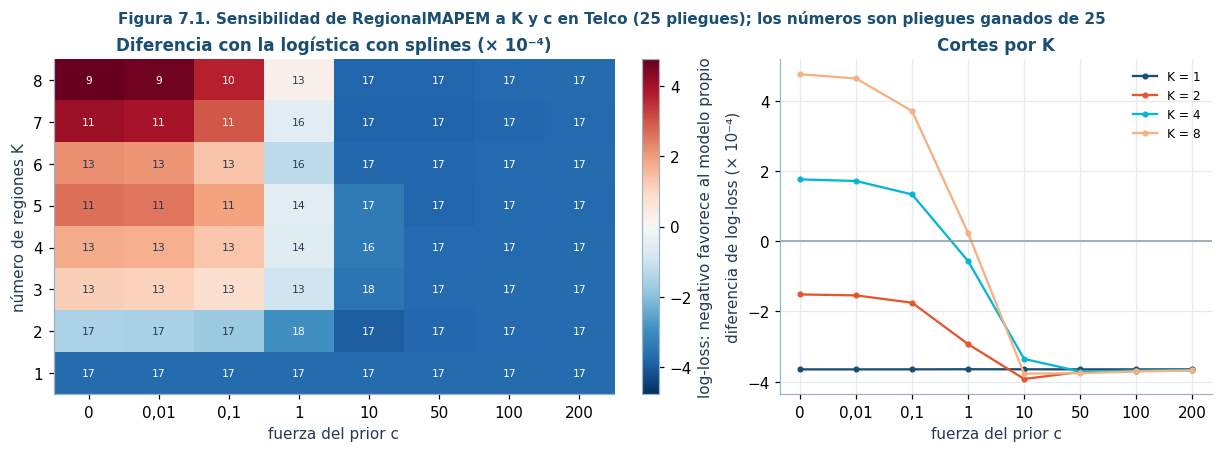

In [5]:
# Superficie de sensibilidad: log-loss medio de RegionalMAPEM para cada (K, c), menos el de la logística con splines
S = pd.read_csv(TAB.parent / "robustez" / "sensibilidad_K_c.csv")
P = POR_PLIEGUE[(POR_PLIEGUE.conjunto == "telco") & (POR_PLIEGUE.modelo == MEJOR)][["rep", "pliegue", "log_loss"]]
S = S.merge(P, on=["rep", "pliegue"], suffixes=("", "_rival"))
S["dif"] = S.log_loss - S.log_loss_rival
M = S.groupby(["K", "c"]).dif.mean().unstack()
gana = S.assign(g=S.dif < 0).groupby(["K", "c"]).g.sum().unstack()
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]})
lim = np.abs(M.values).max() * 1e4
im = ax[0].imshow(M.values * 1e4, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto", origin="lower")
ax[0].set(xticks=range(M.shape[1]), xticklabels=[numero(c, 2).rstrip("0").rstrip(",") for c in M.columns], yticks=range(M.shape[0]),
          yticklabels=M.index, xlabel="fuerza del prior c", ylabel="número de regiones K",
          title="Diferencia con la logística con splines (× 10⁻⁴)")
ax[0].grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax[0].text(j, i, f"{gana.values[i, j]}", ha="center", va="center", fontsize=7, color="white" if abs(M.values[i, j] * 1e4) > 0.6 * lim else "#243B53")
fig.colorbar(im, ax=ax[0], label="log-loss: negativo favorece al modelo propio")
for K in (1, 2, 4, 8):
    ax[1].plot(range(M.shape[1]), M.loc[K].values * 1e4, "o-", ms=3, label=f"K = {K}")
ax[1].axhline(0, color=GRIS, lw=1); ax[1].set(xticks=range(M.shape[1]), xticklabels=ax[0].get_xticklabels() and [numero(c, 2).rstrip("0").rstrip(",") for c in M.columns],
                                               xlabel="fuerza del prior c", ylabel="diferencia de log-loss (× 10⁻⁴)", title="Cortes por K")
ax[1].legend(fontsize=8)
fig.suptitle("Figura 7.1. Sensibilidad de RegionalMAPEM a K y c en Telco (25 pliegues); los números son pliegues ganados de 25",
             color=AZUL, fontweight="bold", fontsize=10)
plt.show()

La superficie cuenta una historia clara. Con $K = 1$ (pesos globales) el modelo queda por delante de la logística con
splines para cualquier $c$. Al agregar regiones, el log-loss empeora cuanto más pequeño es $c$: las regiones sin prior
sobreajustan. Al subir $c$, el prior absorbe las regiones y todas las filas convergen al valor de $K = 1$, unas 0,0004 por
debajo de la logística con splines. Esa ventaja es mayor que la que obtuvo el modelo en la validación anidada (0,00003),
porque allí $K$ y $c$ se eligieron dentro del bucle interno y esa elección, sobre una superficie tan plana, agrega ruido.
Lo decimos solo como lectura exploratoria: fijar $K = 1$ después de ver estos resultados sería ajustar el modelo al
conjunto de evaluación. La región donde
el modelo conserva su ventaja es, por tanto, la de pocos grados de libertad efectivos: $K$ pequeño o $c \ge 10$.

Este es el resultado que explica todo el proyecto. El prior hace lo que prometía, porque protege al modelo cuando las
regiones no aportan, pero en Telco las regiones nunca llegan a aportar. La validación anidada da otra señal de lo mismo:
en los 25 pliegues eligió valores de $K$ entre 1 y 8 y de $c$ entre 0,01 y 195, sin un patrón. Cuando la superficie es
así de plana, el criterio interno no tiene cómo preferir una configuración, y la elección queda en manos del ruido.

## Estabilidad por semilla y por partición

Repetimos el ajuste final de cada modelo con 10 semillas, `seed_for('model', s)` con $s = 0,\dots,9$, sobre los 5
pliegues de la repetición 0. Las cinco repeticiones del bucle externo dan además la variabilidad debida a la partición.

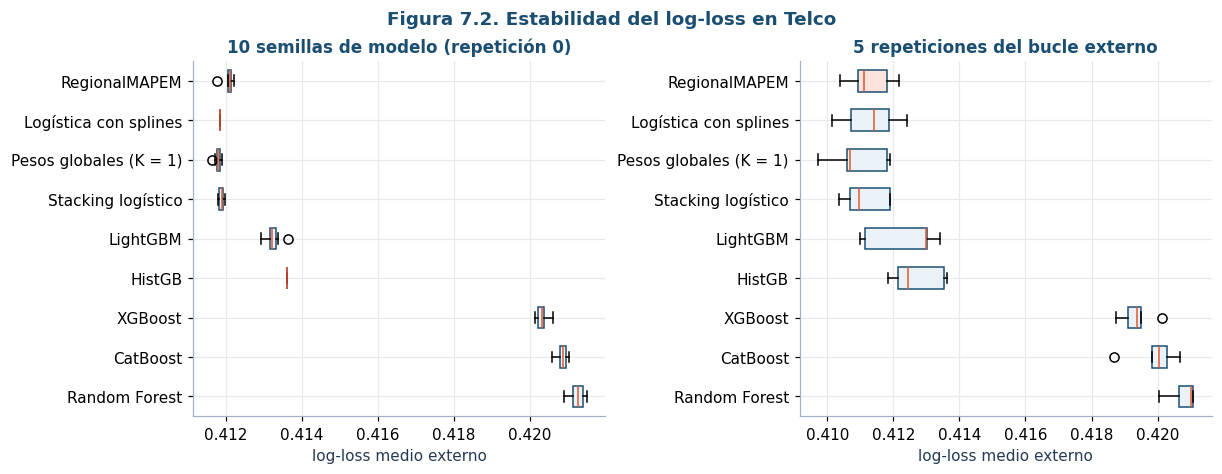

Modelo,Media sobre 10 semillas,Desv. estándar entre semillas (por pliegue),Media sobre 5 repeticiones,Desv. estándar entre repeticiones,Rango entre repeticiones
RegionalMAPEM,"0,41209","0,00024","0,41127","0,00070","0,00177"
Logística con splines,"0,41185","0,00000","0,41130","0,00090","0,00226"
Pesos globales (K = 1),"0,41180","0,00013","0,41094","0,00091","0,00218"
Stacking logístico,"0,41189","0,00012","0,41116","0,00071","0,00155"
LightGBM,"0,41325","0,00039","0,41231","0,00115","0,00243"
HistGB,"0,41362","0,00000","0,41271","0,00082","0,00178"
XGBoost,"0,42032","0,00034","0,41937","0,00052","0,00139"
CatBoost,"0,42085","0,00034","0,41990","0,00075","0,00200"
Random Forest,"0,42125","0,00058","0,42077","0,00045","0,00104"


In [6]:
# Distribución del log-loss medio sobre 10 semillas (izquierda) y sobre las 5 repeticiones de la validación anidada (derecha)
sem = ROB[ROB.escenario.str.startswith("semilla")].groupby(["escenario", "modelo"]).log_loss.mean().unstack()
rep = POR_PLIEGUE[POR_PLIEGUE.conjunto == "telco"].groupby(["rep", "modelo"]).log_loss.mean().unstack()
orden = ["RegionalMAPEM", MEJOR, "mapem_K1", "stacking_logistico", "lightgbm", "hist_gb", "xgboost", "catboost", "random_forest"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", sharey=False)
for a, D, t in ((ax[0], sem, "10 semillas de modelo (repetición 0)"), (ax[1], rep, "5 repeticiones del bucle externo")):
    b = a.boxplot([D[m].values for m in orden], vert=False, widths=0.55, patch_artist=True, medianprops=dict(color=RIESGO))
    for caja, m in zip(b["boxes"], orden):
        caja.set(facecolor="#EAF2F8" if m != "RegionalMAPEM" else "#FCE3DC", edgecolor=AZUL)
    a.set(yticks=range(1, len(orden) + 1), yticklabels=[NOMBRES[m] for m in orden], xlabel="log-loss medio externo", title=t)
    a.invert_yaxis()
fig.suptitle("Figura 7.2. Estabilidad del log-loss en Telco", color=AZUL, fontweight="bold")
plt.show()
de_sem = ROB[ROB.escenario.str.startswith("semilla")].groupby(["modelo", "pliegue"]).log_loss.std().groupby("modelo").mean()
tabla(pd.DataFrame({"Modelo": [NOMBRES[m] for m in orden], "Media sobre 10 semillas": [sem[m].mean() for m in orden],
                    "Desv. estándar entre semillas (por pliegue)": [de_sem[m] for m in orden],
                    "Media sobre 5 repeticiones": [rep[m].mean() for m in orden], "Desv. estándar entre repeticiones": [rep[m].std() for m in orden],
                    "Rango entre repeticiones": [rep[m].max() - rep[m].min() for m in orden]}),
      "Tabla 7.5. Variabilidad por semilla y por partición", decimales=5, buscar=False)

La semilla casi no mueve a ninguno: la desviación entre semillas del modelo propio es de 0,0002, y la logística con
splines y HistGB son deterministas. La partición pesa bastante más (entre 0,0007 y 0,0009 en los modelos de arriba), así
que la diferencia de 0,00003 con el mejor benchmark es unas 25 veces menor que la variación que produce cambiar de
partición. Ese es el tamaño real del empate.

## Ruido y valores atípicos

Contaminamos el pliegue de ajuste de cuatro formas: ruido gaussiano de $0{,}5\,\sigma$ en las tres variables numéricas
(`tenure`, `MonthlyCharges`, `TotalCharges`) en el 5, 10 y 20 % de los clientes; valores atípicos en media $\pm 5\,\sigma$
en el 1 y 5 %; y etiquetas invertidas en el 5 y 10 %. La evaluación se hace siempre sobre clientes limpios.

Escenario,RegionalMAPEM,Logística con splines,Pesos globales (K = 1),Stacking logístico,HistGB,CatBoost,Naive Bayes,kNN,Diferencia propio − splines
Sin perturbar,"0,4122","0,4119","0,4118","0,4119","0,4136","0,4207","0,4481","0,4324","0,0003"
"Ruido en X, 5 %","0,4123","0,4120","0,4121","0,4125","0,4134","0,4205","0,4456","0,4317","0,0003"
"Ruido en X, 10 %","0,4125","0,4129","0,4123","0,4127","0,4139","0,4206","0,4454","0,4331","−0,0004"
"Ruido en X, 20 %","0,4132","0,4132","0,4132","0,4131","0,4144","0,4205","0,4451","0,4324","4,00e−05"
"Atípicos, 1 %","0,4119","0,4126","0,4121","0,4125","0,4135","0,4205","0,4460","0,4330","−0,0007"
"Atípicos, 5 %","0,4128","0,4138","0,4132","0,4135","0,4140","0,4207","0,4490","0,4346","−0,0010"
"Etiquetas invertidas, 5 %","0,4240","0,4221","0,4237","0,4217","0,4232","0,4267","0,4508","0,4391","0,0019"
"Etiquetas invertidas, 10 %","0,4441","0,4443","0,4435","0,4401","0,4446","0,4432","0,4613","0,4571","−0,0002"


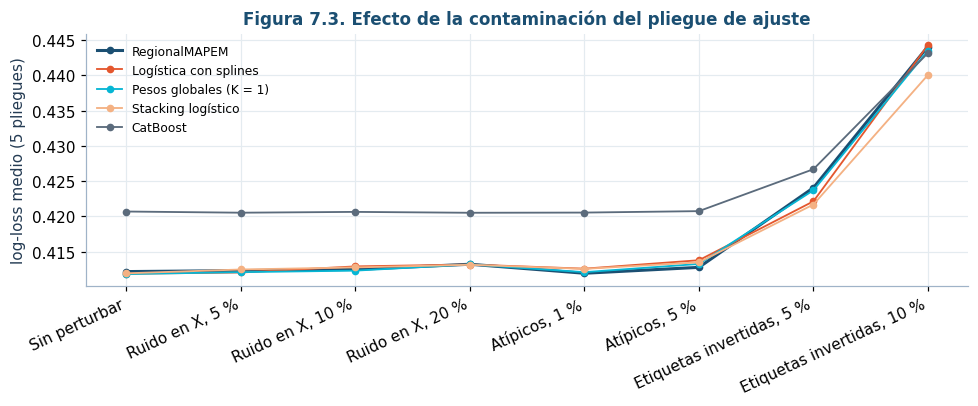

In [7]:
# Log-loss medio de los 5 pliegues bajo cada perturbación, frente a la referencia sin perturbar (validación anidada, rep. 0)
esc = {"Sin perturbar": None, "Ruido en X, 5 %": "ruido_x_05", "Ruido en X, 10 %": "ruido_x_10", "Ruido en X, 20 %": "ruido_x_20",
       "Atípicos, 1 %": "atipicos_01", "Atípicos, 5 %": "atipicos_05", "Etiquetas invertidas, 5 %": "ruido_y_05", "Etiquetas invertidas, 10 %": "ruido_y_10"}
base = BASE0.groupby("modelo").log_loss.mean()
filas = []
for nombre, e in esc.items():
    v = base if e is None else ROB[ROB.escenario == e].groupby("modelo").log_loss.mean()
    filas.append({"Escenario": nombre, **{NOMBRES[m]: v[m] for m in FOCO + ["naive_bayes", "knn"]},
                  "Diferencia propio − splines": v["RegionalMAPEM"] - v[MEJOR]})
tabla(pd.DataFrame(filas), "Tabla 7.6. Log-loss medio en Telco con datos de ajuste contaminados", decimales=4, buscar=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(esc))
for m in FOCO[:4] + ["catboost"]:
    v = [base[m] if e is None else ROB[ROB.escenario == e].groupby("modelo").log_loss.mean()[m] for e in esc.values()]
    ax.plot(x, v, "o-", ms=4, label=NOMBRES[m], lw=2 if m == "RegionalMAPEM" else 1.2)
ax.set(xticks=x, xticklabels=list(esc), ylabel="log-loss medio (5 pliegues)", title="Figura 7.3. Efecto de la contaminación del pliegue de ajuste")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

El ruido en las variables y los atípicos casi no afectan a nadie: con el 20 % de ruido el modelo propio pierde 0,001.
Es lógico, porque las variables numéricas de Telco están muy correlacionadas con las categóricas de contrato y servicio,
que no se tocaron. Invertir etiquetas sí duele, y de forma parecida a todos: con el 10 % el log-loss sube unos 0,03. En
ningún escenario cambia el orden de fondo: el modelo propio y la logística con splines siguen empatados, a menos de 0,002.

## Tamaño de muestra y escalabilidad

La curva de aprendizaje usa el 10, 25, 50 y 100 % del pliegue de ajuste, con muestreo estratificado.

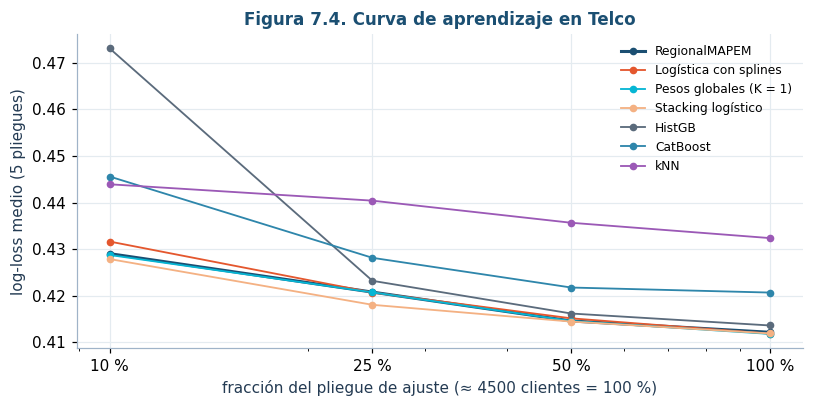

Modelo,10 %,25 %,50 %,100 %
RegionalMAPEM,"0,4290","0,4208","0,4146","0,4122"
Logística con splines,"0,4316","0,4207","0,4152","0,4119"
Pesos globales (K = 1),"0,4287","0,4207","0,4146","0,4118"
Stacking logístico,"0,4279","0,4181","0,4144","0,4119"
HistGB,"0,4731","0,4232","0,4162","0,4136"
CatBoost,"0,4456","0,4281","0,4218","0,4207"
kNN,"0,4439","0,4404","0,4357","0,4324"


In [8]:
# Curva de aprendizaje (100 % = validación anidada, repetición 0)
fr = {"10 %": "n_10", "25 %": "n_25", "50 %": "n_50", "100 %": None}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
filas = []
for m in FOCO + ["knn"]:
    v = [base[m] if e is None else ROB[ROB.escenario == e].groupby("modelo").log_loss.mean()[m] for e in fr.values()]
    ax.plot([10, 25, 50, 100], v, "o-", ms=4, label=NOMBRES[m], lw=2 if m == "RegionalMAPEM" else 1.2)
    filas.append({"Modelo": NOMBRES[m], **dict(zip(fr, v))})
ax.set(xscale="log", xticks=[10, 25, 50, 100], xticklabels=["10 %", "25 %", "50 %", "100 %"], xlabel="fracción del pliegue de ajuste (≈ 4500 clientes = 100 %)",
       ylabel="log-loss medio (5 pliegues)", title="Figura 7.4. Curva de aprendizaje en Telco")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
tabla(pd.DataFrame(filas), "Tabla 7.7. Log-loss medio según el tamaño del pliegue de ajuste", decimales=4, buscar=False)

Con poco dato, los modelos que combinan expertos sacan ventaja: con el 10 % (unos 450 clientes) el modelo propio le gana a
la logística con splines por 0,003 y a HistGB por 0,044, que se desploma. Esa es una ventaja real de combinar, pero la
comparten los pesos globales y el stacking. A partir del 25 % las diferencias vuelven a ser mínimas.

Para la escalabilidad medimos el tiempo de ajuste con datos sintéticos, variando $n$ con $p = 20$ y $p$ con $n = 2000$,
con un solo proceso para que los tiempos sean comparables. Para el modelo propio se mide solo lo que agrega sobre los
expertos: las regiones (PCA y GMM) y el MAP-EM.

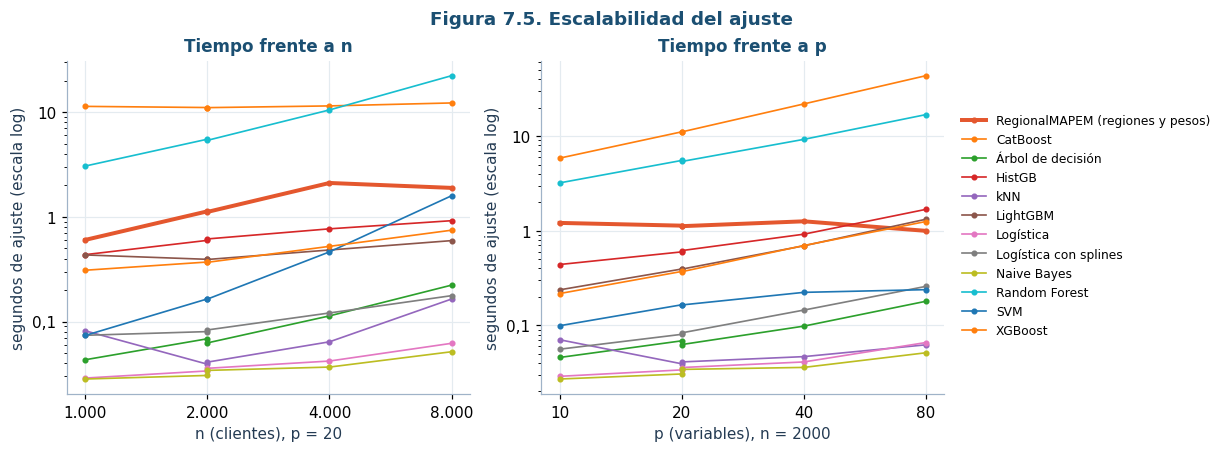

Modelo,Ajuste en Telco (s),Predicción (ms por 1000),Pico de memoria de Python (MB),Tamaño serializado (MB)
kNN,"0,48","181,61","9,35","1,81"
Naive Bayes,"0,24","25,22","4,41","0,01"
Logística,"0,30","27,96","4,41","9,35e−03"
Árbol de decisión,"0,27","25,99","4,40","0,03"
Random Forest,"6,60","102,56","4,81","15,38"
XGBoost,"0,77","30,29","4,42","1,17"
SVM,"0,84","246,04","5,05","0,92"
Logística con splines,"0,32","29,32","5,97","0,04"
HistGB,"3,93","157,91","7,08","1,58"
LightGBM,"1,07","96,35","4,44","1,49"


In [9]:
# Tiempo de ajuste según n y p (datos sintéticos, 1 proceso) y memoria por modelo en Telco
ES = pd.read_csv(TAB / "escalabilidad.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
paleta = plt.get_cmap("tab20").colors
for i, (m, g) in enumerate(ES.groupby("modelo")):
    nombre = "RegionalMAPEM (regiones y pesos)" if m.startswith("RegionalMAPEM") else NOMBRES[m]
    estilo = dict(lw=2.6, color=RIESGO) if m.startswith("RegionalMAPEM") else dict(lw=1.1, color=paleta[(2 * i) % 20])
    gn, gp = g[g.p == 20].sort_values("n"), g[g.n == 2000].sort_values("p")
    ax[0].plot(gn.n, gn.seg_ajuste, "o-", ms=3, label=nombre, **estilo); ax[1].plot(gp.p, gp.seg_ajuste, "o-", ms=3, **estilo)
ax[0].set(xscale="log", yscale="log", xlabel="n (clientes), p = 20", ylabel="segundos de ajuste (escala log)", title="Tiempo frente a n")
ax[1].set(xscale="log", yscale="log", xlabel="p (variables), n = 2000", ylabel="segundos de ajuste (escala log)", title="Tiempo frente a p")
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter
for a, marcas in ((ax[0], [1000, 2000, 4000, 8000]), (ax[1], [10, 20, 40, 80])):
    a.xaxis.set_major_locator(FixedLocator(marcas)); a.xaxis.set_minor_locator(NullLocator())
    a.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", ".")))
    a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: numero(v, 2).rstrip("0").rstrip(",")))
fig.legend(loc="outside right center", fontsize=8)
fig.suptitle("Figura 7.5. Escalabilidad del ajuste", color=AZUL, fontweight="bold"); plt.show()
MEM = pd.read_csv(TAB / "memoria_por_modelo.csv")
tabla(pd.DataFrame({"Modelo": MEM.modelo.map(NOMBRES), "Ajuste en Telco (s)": MEM.seg_ajuste, "Predicción (ms por 1000)": 1000 * MEM.seg_pred_por_1000,
                    "Pico de memoria de Python (MB)": MEM.pico_python_mb, "Tamaño serializado (MB)": MEM.tamano_serializado_mb}),
      "Tabla 7.8. Costo por modelo en Telco (repetición 0, pliegue 0, 1 proceso)", decimales=2, buscar=False,
      nota="El pico de memoria lo mide tracemalloc y no incluye las asignaciones nativas de las librerías compiladas.")

La parte propia del modelo cuesta entre 0,6 y 2 segundos y casi no depende de $p$, porque las regiones se construyen sobre
dos componentes principales. El costo total del modelo, en cambio, es el de los once expertos más ese poco: en
producción, Random Forest y CatBoost dominan el tiempo y el tamaño, y un ensamble de este tipo pesa unos 23 MB
serializado.

## Cambio de distribución

Dos corridas únicas del procedimiento completo, con el mismo presupuesto. En la primera, todos los modelos se ajustaron
con los clientes de desarrollo con tenure de hasta 24 meses (2555) y se evaluaron con los de más de 24 (3079): una
población más fiel, con la mitad de churn. La segunda es el hold-out final: ajuste con los 5634 de desarrollo y una sola
evaluación sobre los 1409 clientes reservados desde el principio del proyecto.

In [10]:
# Métricas de las dos corridas únicas
F = pd.read_csv(LIB / "corridas_finales.csv")
for cual, t in (("tenure", "Tabla 7.9. Entrenar con tenure ≤ 24 y evaluar con tenure > 24"), ("holdout", "Tabla 7.10. Evaluación única sobre el hold-out")):
    g = F[F.corrida == cual].sort_values("log_loss")
    tabla(pd.DataFrame({"Modelo": g.modelo.map(NOMBRES), "Log-loss": g.log_loss, "F1": g.f1, "AUC": g.auc, "Brier": g.brier, "ECE": g.ece, "Umbral": g.umbral}),
          t, decimales=4, nota=f"{int(g.n.iloc[0])} clientes de evaluación, {numero(100 * g.churn.iloc[0], 1)} % de churn. "
                               "El umbral de F1 se fija con predicciones fuera de pliegue del conjunto de ajuste.")

Modelo,Log-loss,F1,AUC,Brier,ECE,Umbral
Stacking logístico,"0,3291","0,4544","0,8192","0,0998","0,0247","0,3209"
MAP-EM sin prior,"0,3327","0,4482","0,8134","0,1025","0,0316","0,3159"
Pesos globales (K = 1),"0,3327","0,4482","0,8134","0,1025","0,0316","0,3159"
Regiones duras,"0,3327","0,4482","0,8134","0,1025","0,0316","0,3159"
RegionalMAPEM,"0,3327","0,4482","0,8134","0,1025","0,0316","0,3159"
HistGB,"0,3338","0,4559","0,8144","0,1037","0,0395","0,3474"
LightGBM,"0,3481","0,4432","0,8084","0,1076","0,0659","0,3347"
Logística con splines,"0,3485","0,4498","0,8105","0,1037","0,0402","0,3510"
XGBoost,"0,3573","0,4437","0,8065","0,1076","0,0758","0,3013"
Promedio simple,"0,3617","0,4633","0,8033","0,1086","0,0846","0,3219"


Modelo,Log-loss,F1,AUC,Brier,ECE,Umbral
MAP-EM sin prior,"0,4106","0,6349","0,8499","0,1339","0,0105","0,3212"
RegionalMAPEM,"0,4109","0,6359","0,8496","0,1340","0,0109","0,3201"
Regiones duras,"0,4112","0,6327","0,8496","0,1340","0,0135","0,3241"
Pesos globales (K = 1),"0,4118","0,6371","0,8490","0,1342","0,0138","0,3316"
Stacking logístico,"0,4121","0,6312","0,8492","0,1343","0,0186","0,3138"
Logística con splines,"0,4122","0,6278","0,8477","0,1343","0,0143","0,2908"
LightGBM,"0,4128","0,6309","0,8486","0,1345","0,0159","0,3145"
HistGB,"0,4130","0,6330","0,8482","0,1347","0,0166","0,3178"
Promedio simple,"0,4183","0,6295","0,8465","0,1355","0,0266","0,2838"
XGBoost,"0,4208","0,6334","0,8486","0,1354","0,0391","0,2731"


Con el cambio de población por tenure, los cinco primeros puestos son combinadores: el stacking logístico gana (0,3291) y
el modelo propio queda quinto (0,3327), empatado con los pesos globales y por delante de HistGB (0,3338) y de la logística
con splines (0,3485). Aquí la validación anidada eligió $K = 1$, así que el modelo coincide exactamente con los pesos
globales. Es el escenario donde más se nota la calibración: los combinadores tienen ECE de 0,025 a 0,032, mientras CatBoost
y XGBoost llegan a 0,08. La logística sin splines se desarma (F1 de 0,28): no logra extrapolar a clientes con más
antigüedad.

En el hold-out, el modelo propio queda segundo de 17 en log-loss (0,4109), en AUC (0,8496) y en calibración (ECE de 0,011),
en los tres casos detrás de su variante sin prior y por delante de todos los benchmarks. Las diferencias con la logística
con splines no son significativas (capítulo 6, tabla 6.4), pero son coherentes con lo visto en desarrollo: el modelo
nunca pierde frente a ella y a veces gana por poco.

## Calibración y reglas de puntuación

Como la métrica principal es una regla de puntuación propia, la calidad de las probabilidades es lo que más importa. La
figura 7.6 muestra las curvas de calibración con las predicciones externas de las cinco repeticiones (cada cliente aparece
cinco veces).

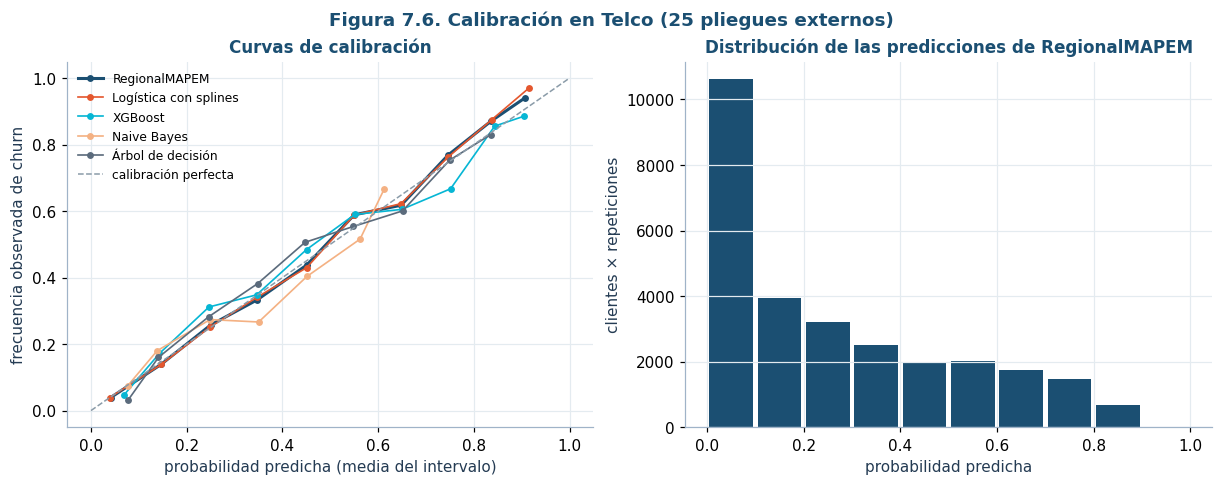

Modelo,ECE,Brier,Log-loss
Logística con splines,"0,0243","0,1330","0,4113"
Logística,"0,0244","0,1352","0,4171"
Regiones duras,"0,0251","0,1331","0,4114"
Pesos globales (K = 1),"0,0252","0,1330","0,4109"
HistGB,"0,0253","0,1337","0,4127"
RegionalMAPEM,"0,0254","0,1331","0,4113"
MAP-EM sin prior,"0,0266","0,1332","0,4117"
LightGBM,"0,0272","0,1335","0,4123"
Stacking logístico,"0,0273","0,1331","0,4112"
Promedio simple,"0,0311","0,1338","0,4152"


In [11]:
# Curvas de calibración (10 intervalos de igual ancho) con las predicciones del bucle externo de Telco
CAL = pd.read_csv(LIB / "calibracion_telco.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
for m in ["RegionalMAPEM", MEJOR, "xgboost", "naive_bayes", "decision_tree"]:
    g = CAL[CAL.modelo == m]
    ax[0].plot(g.p_media, g.frecuencia_observada, "o-", ms=3.5, label=NOMBRES[m], lw=2 if m == "RegionalMAPEM" else 1.1)
ax[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="calibración perfecta")
ax[0].set(xlabel="probabilidad predicha (media del intervalo)", ylabel="frecuencia observada de churn", title="Curvas de calibración"); ax[0].legend(fontsize=8)
g = CAL[CAL.modelo == "RegionalMAPEM"]
ax[1].bar(g.bin / 10 + 0.05, g.n, width=0.09, color=AZUL); ax[1].set(xlabel="probabilidad predicha", ylabel="clientes × repeticiones", title="Distribución de las predicciones de RegionalMAPEM")
fig.suptitle("Figura 7.6. Calibración en Telco (25 pliegues externos)", color=AZUL, fontweight="bold"); plt.show()
r = RESUMEN[RESUMEN.conjunto == "telco"].sort_values("ece_media")
tabla(pd.DataFrame({"Modelo": r.modelo.map(NOMBRES), "ECE": r.ece_media, "Brier": r.brier_media, "Log-loss": r.log_loss_media}),
      "Tabla 7.11. Error de calibración esperado y puntuaciones propias en Telco (medias de 25 pliegues)", decimales=4)

Todas las curvas siguen de cerca la diagonal, porque cada modelo se calibró con Platt dentro del bucle interno. Las
desviaciones más visibles son las de XGBoost, que entre 0,7 y 0,9 asigna más probabilidad de la que se observa, y las de
Naive Bayes, que casi nunca predice por encima de 0,6 y se aparta de la diagonal en el tramo medio. El modelo propio y
la logística con splines siguen pegados a la diagonal en todo el rango. La mayoría de los clientes recibe probabilidades
bajas, lo que refleja que tres de cada cuatro no abandonan. La ECE de RegionalMAPEM (0,025)
es de las más bajas, junto con la de la logística con splines, la regresión logística y los pesos globales.

## Cuantificación de la incertidumbre

Para cada modelo construimos conjuntos de predicción con predicción conforme partida y condicionada por clase (Mondrian) {cite}`vovk2005`.
Reservamos el 25 % del pliegue de ajuste para calibrar los cuantiles y ajustamos los expertos y los pesos con el 75 %
restante. Un conjunto puede ser {churn}, {no churn} o {churn, no churn} cuando el modelo no tiene suficiente certeza.

In [12]:
# Cobertura empírica frente a la nominal y tamaño medio de los conjuntos (5 pliegues, repetición 0)
CF = pd.read_csv(LIB / "conforme.csv")
g = CF.groupby(["modelo", "nominal"])[["cobertura", "cobertura_churn", "cobertura_no_churn", "tamano_medio", "singleton"]].mean().reset_index()
g = g[g.modelo.isin(FOCO + ["naive_bayes", "knn", "xgboost"])].sort_values(["nominal", "tamano_medio"])
tabla(pd.DataFrame({"Modelo": g.modelo.map(NOMBRES), "Cobertura nominal": g.nominal, "Cobertura empírica": g.cobertura,
                    "Cobertura en churn": g.cobertura_churn, "Cobertura en no churn": g.cobertura_no_churn,
                    "Tamaño medio del conjunto": g.tamano_medio, "% de conjuntos con una sola clase": 100 * g.singleton}),
      "Tabla 7.12. Predicción conforme de Mondrian en Telco", decimales=3)

Modelo,Cobertura nominal,Cobertura empírica,Cobertura en churn,Cobertura en no churn,Tamaño medio del conjunto,% de conjuntos con una sola clase
Stacking logístico,"0,900","0,895","0,902","0,892","1,311","68,902"
CatBoost,"0,900","0,896","0,901","0,894","1,313","68,725"
Pesos globales (K = 1),"0,900","0,896","0,908","0,892","1,315","68,512"
XGBoost,"0,900","0,898","0,906","0,894","1,315","68,476"
RegionalMAPEM,"0,900","0,897","0,907","0,893","1,316","68,441"
Logística con splines,"0,900","0,898","0,907","0,894","1,317","68,335"
HistGB,"0,900","0,898","0,905","0,896","1,318","68,175"
kNN,"0,900","0,893","0,900","0,890","1,349","65,104"
Naive Bayes,"0,900","0,894","0,899","0,893","1,359","64,057"
Logística con splines,"0,950","0,940","0,946","0,938","1,486","51,402"


La cobertura empírica queda muy cerca de la nominal en todos los modelos, también por clase: es lo que garantiza la
construcción de Mondrian y la tabla lo verifica. Al 90 %, el modelo propio da una sola clase al 68 % de los clientes y
duda en el resto; al 95 %, solo a la mitad. La diferencia con la logística con splines es otra vez despreciable. Para un
equipo de retención, esto sirve más que la probabilidad sola: un tercio de los clientes queda marcado como caso incierto
que conviene revisar antes de actuar.

## Análisis de errores

¿Dónde falla el modelo y dónde no supera al mejor benchmark? La tabla 7.13 divide los clientes de evaluación de la
repetición 0 por tipo de contrato y por antigüedad.

In [13]:
# Log-loss por subgrupo en los 5 pliegues de la repetición 0 (promedio ponderado por clientes)
ER = pd.read_csv(LIB / "errores_subgrupos.csv")
def por_grupo(g):
    w = g.groupby(["valor", "modelo"]).apply(lambda d: pd.Series({"n": d.n.sum(), "ll": np.average(d.log_loss, weights=d.n),
                                                                     "churn": np.average(d.churn, weights=d.n)}), include_groups=False).unstack("modelo")
    return pd.DataFrame({"Clientes": w[("n", "RegionalMAPEM")].astype(int), "% churn": 100 * w[("churn", "RegionalMAPEM")],
                         "RegionalMAPEM": w[("ll", "RegionalMAPEM")], NOMBRES[MEJOR]: w[("ll", MEJOR)], "Pesos globales": w[("ll", "mapem_K1")],
                         "Diferencia propio − splines": w[("ll", "RegionalMAPEM")] - w[("ll", MEJOR)]}).reset_index().rename(columns={"valor": "Subgrupo"})
etiqueta = {"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años"}
c = por_grupo(ER[ER.grupo == "contrato"]); c["Subgrupo"] = "Contrato: " + c.Subgrupo.map(etiqueta)
t = por_grupo(ER[ER.grupo == "tenure"]); t["Subgrupo"] = "Tenure: " + t.Subgrupo + " meses"
tabla(pd.concat([c, t]), "Tabla 7.13. Log-loss por tipo de contrato y antigüedad (repetición 0)", decimales=4, buscar=False)

Subgrupo,Clientes,% churn,RegionalMAPEM,Logística con splines,Pesos globales,Diferencia propio − splines
Contrato: Mes a mes,3.102,"42,7466","0,5726","0,5726","0,5728","−1,88e−05"
Contrato: Un año,1.173,"11,0827","0,3248","0,3246","0,3231","0,0003"
Contrato: Dos años,1.359,"2,8698","0,1213","0,1202","0,1208","0,0011"
Tenure: 0-12 meses,1.737,"47,3230","0,5436","0,5436","0,5434","7,31e−05"
Tenure: 13-24 meses,818,"28,6064","0,4683","0,4679","0,4685","0,0004"
Tenure: 25-48 meses,1.290,"20,2326","0,4035","0,4040","0,4036","−0,0005"
Tenure: 49-72 meses,1.789,"9,9497","0,2650","0,2639","0,2640","0,0011"


El error se concentra donde está el churn. Los contratos mes a mes y los clientes del primer año tienen log-loss de
0,54 a 0,57, porque ahí la incertidumbre es genuina: casi la mitad abandona. Los contratos de dos años, con un 3 % de
churn, son fáciles para todos. Las diferencias con la logística con splines no superan 0,0011 en ningún subgrupo, y
donde el modelo propio pierde un poco es justamente en los segmentos más estables (contratos de dos años, más de 49
meses), donde la combinación tiende a suavizar probabilidades que la logística deja más extremas.

Las regiones del propio modelo permiten mirar más fino. Como cada pliegue tiene su propio GMM, con un número distinto de
regiones, la tabla 7.14 las muestra pliegue por pliegue.

In [14]:
# Log-loss por región en cada pliegue (las regiones no se corresponden entre pliegues)
R = ER[ER.grupo == "region"].pivot_table(index=["pliegue", "valor"], columns="modelo", values=["log_loss", "n", "churn"]).reset_index()
vista = pd.DataFrame({"Pliegue": R["pliegue"], "Región": R["valor"], "K del pliegue": R["pliegue"].map(ER.groupby("pliegue").K.first()),
                      "Clientes": R[("n", "RegionalMAPEM")].astype(int), "% churn": 100 * R[("churn", "RegionalMAPEM")],
                      "RegionalMAPEM": R[("log_loss", "RegionalMAPEM")], NOMBRES[MEJOR]: R[("log_loss", MEJOR)],
                      "Pesos globales": R[("log_loss", "mapem_K1")], "Diferencia propio − splines": R[("log_loss", "RegionalMAPEM")] - R[("log_loss", MEJOR)]})
tabla(vista, "Tabla 7.14. Log-loss por región dura en cada pliegue de la repetición 0", decimales=4)

Pliegue,Región,K del pliegue,Clientes,% churn,RegionalMAPEM,Logística con splines,Pesos globales,Diferencia propio − splines
0,región 0,6,80,"6,2500","0,2061","0,2106","0,2053","−0,0045"
0,región 1,6,11,"18,1818","0,5414","0,5225","0,5344","0,0189"
0,región 2,6,22,"90,9091","0,4328","0,4557","0,4366","−0,0229"
0,región 3,6,222,"17,1171","0,4021","0,4016","0,3986","0,0005"
0,región 4,6,519,"42,3892","0,5815","0,5803","0,5799","0,0012"
0,región 5,6,273,"5,1282","0,1820","0,1835","0,1828","−0,0015"
1,región 0,5,252,"17,4603","0,4221","0,4236","0,4222","−0,0015"
1,región 1,5,94,"6,3830","0,1999","0,1888","0,1901","0,0111"
1,región 2,5,24,"70,8333","0,5598","0,5356","0,5334","0,0242"
1,región 3,5,472,"44,9153","0,5737","0,5737","0,5738","−2,77e−05"


En las regiones grandes (cientos de clientes), las diferencias con la logística con splines son de milésimas, a favor de
uno u otro. Las diferencias de 0,02 aparecen solo en regiones de 11 a 30 clientes, y van en ambos sentidos: en el pliegue
0 el modelo gana en una región de 22 clientes con 91 % de churn y pierde en otra de 11. Ese patrón, sin una dirección
estable, es el de la variación muestral y no el de una fiabilidad de expertos que cambie con el tipo de cliente. Es la
misma conclusión de la ablación, vista desde los errores.

## Interpretabilidad

Calculamos valores SHAP {cite}`lundberg2017` (KernelExplainer, con enlace identidad) del modelo propio y de la logística con splines sobre 200
clientes del pliegue de evaluación de la repetición 0, con 100 clientes de fondo del pliegue de ajuste. Los dos modelos se
explican sobre las 19 variables originales, antes del preprocesamiento, para que la comparación sea directa.

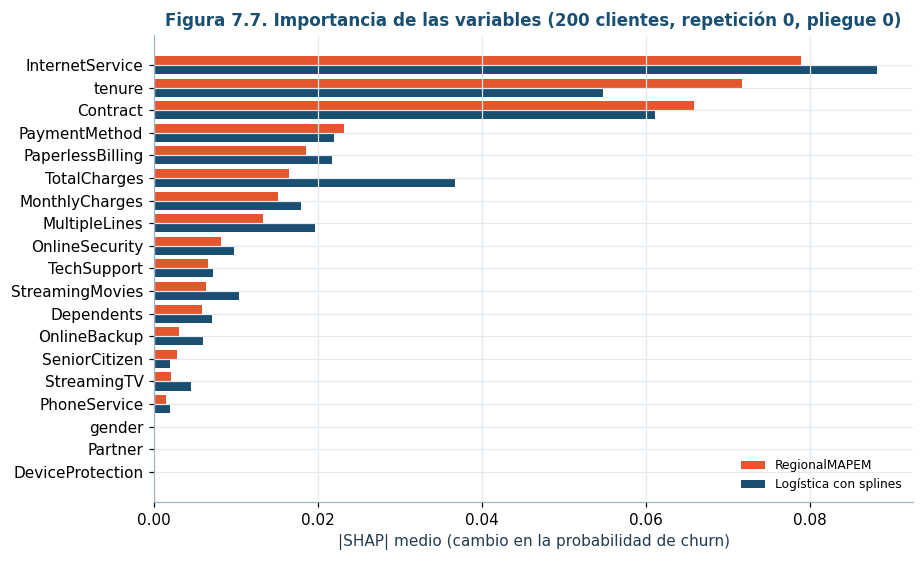

Región,kNN,Naive Bayes,Logística,Árbol de decisión,Random Forest,XGBoost,SVM,Logística con splines,HistGB,LightGBM,CatBoost
Región 0,"4,01e−11","1,32e−05","0,026","0,035","4,78e−05","2,30e−08","2,99e−06","0,588","0,294","0,056","4,65e−05"
Región 1,"4,06e−11","4,16e−06","0,007","0,065","3,00e−05","2,62e−08","5,19e−07","0,329","0,541","0,058","4,91e−05"
Región 2,"1,86e−11","7,76e−06","0,013","0,061","0,047","5,04e−08","1,33e−06","0,479","0,353","0,046","5,17e−04"
Región 3,"1,98e−07","0,146","0,025","0,038","4,96e−05","3,32e−07","4,89e−04","0,518","0,240","0,032","9,69e−05"
Región 4,"1,27e−11","0,007","0,013","0,211","4,23e−05","9,02e−08","7,33e−07","0,478","0,261","0,022","0,007"
Región 5,"1,80e−11","5,76e−06","0,027","0,009","2,46e−05","7,25e−09","3,25e−07","0,421","0,478","0,064","1,48e−05"


In [15]:
# Importancia SHAP media absoluta y pesos por región del modelo ajustado en el pliegue 0
SH = pd.read_csv(TAB / "shap_importancia.csv", index_col=0)
SH = SH.sort_values("RegionalMAPEM")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(SH))
ax.barh(y + 0.2, SH["RegionalMAPEM"], height=0.4, color=RIESGO, label="RegionalMAPEM")
ax.barh(y - 0.2, SH[MEJOR], height=0.4, color=AZUL, label=NOMBRES[MEJOR])
ax.set(yticks=y, yticklabels=SH.index, xlabel="|SHAP| medio (cambio en la probabilidad de churn)",
       title="Figura 7.7. Importancia de las variables (200 clientes, repetición 0, pliegue 0)")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
W = pd.read_csv(TAB / "pesos_por_region_r0_f0.csv")
W = W.rename(columns={"region": "Región"} | {m: NOMBRES[m] for m in W.columns if m in NOMBRES})
W["Región"] = "Región " + W["Región"].astype(str)
tabla(W, "Tabla 7.15. Pesos de cada experto por región en el modelo del pliegue 0 (K = 6)", decimales=3, buscar=False)

Los dos modelos coinciden en lo esencial: el tipo de servicio de internet, la antigüedad y el tipo de contrato explican la
mayor parte de sus predicciones. La diferencia más visible es que el modelo propio
le da menos de la mitad del peso a `TotalCharges`, que es casi el producto de `tenure` por `MonthlyCharges`: al combinar
once expertos, la información redundante se reparte.

Los pesos por región muestran por qué las regiones no aportan. En las seis, casi todo el peso va a la logística con
splines y a HistGB, en proporciones parecidas. kNN, SVM, Random Forest y XGBoost reciben peso nulo o casi nulo en todas
las regiones. Si la fiabilidad de los expertos cambiara de verdad entre tipos de cliente, esta tabla mostraría expertos
distintos dominando regiones distintas. Lo que muestra es el mismo par de expertos en todas partes.

## Las combinaciones del dashboard

Las siete combinaciones del entregable anterior se eligieron por F1 y varias usan SMOTE. Las evaluamos en log-loss sobre
los mismos 25 pliegues, con los hiperparámetros que había elegido aquel entregable, como prevé el protocolo. Esta
comparación favorece a esas combinaciones: en las repeticiones 1 a 4, sus hiperparámetros ya vieron parte de los datos de
evaluación.

In [16]:
# Combinaciones del entregable anterior (seleccionadas por F1) frente a las versiones calibradas de este protocolo
D = pd.read_csv(TAB / "combinaciones_dashboard.csv")
g = D.groupby(["modelo", "combinacion"])[["log_loss", "f1", "auc", "brier", "ece"]].mean().reset_index()
cal = RESUMEN[RESUMEN.conjunto == "telco"].set_index("modelo")
g["ll_cal"] = g.modelo.map(cal.log_loss_media); g["ece_cal"] = g.modelo.map(cal.ece_media)
tabla(pd.DataFrame({"Modelo": g.modelo.map(NOMBRES), "Combinación del entregable anterior": g.combinacion.str.replace("__", " · "),
                    "Log-loss": g.log_loss, "F1": g.f1, "AUC": g.auc, "ECE": g.ece,
                    "Log-loss de la versión calibrada": g.ll_cal, "ECE de la versión calibrada": g.ece_cal}).sort_values("Log-loss"),
      "Tabla 7.16. Combinaciones del dashboard frente a las versiones reajustadas y calibradas (Telco, 25 pliegues)", decimales=4, buscar=False,
      nota=f"RegionalMAPEM: log-loss {numero(cal.loc['RegionalMAPEM', 'log_loss_media'], 4)}, ECE {numero(cal.loc['RegionalMAPEM', 'ece_media'], 4)}.")

Modelo,Combinación del entregable anterior,Log-loss,F1,AUC,ECE,Log-loss de la versión calibrada,ECE de la versión calibrada
XGBoost,xgboost · smote · random,"0,4514","0,6330","0,8462","0,1024","0,4194","0,0416"
Random Forest,random_forest · smote · bayesian_tpe,"0,4591","0,6343","0,8447","0,1116","0,4208","0,0379"
Logística,logistic · smote · grid,"0,4882","0,6326","0,8431","0,1445","0,4171","0,0244"
SVM,svm · smote · genetic,"0,4902","0,6295","0,8396","0,1379","0,4290","0,0322"
Árbol de decisión,decision_tree · smote · bayesian_tpe,"0,5437","0,6073","0,8222","0,1261","0,4328","0,0446"
kNN,knn · smote · bayesian_tpe,"0,5674","0,6103","0,8296","0,1740","0,4304","0,0324"
Naive Bayes,naive_bayes · none · random,"1,0696","0,6206","0,8291","0,2066","0,4479","0,0316"


Las combinaciones seleccionadas por F1 compiten bien en esa métrica (de 0,61 a 0,63), pero sus probabilidades están mal
calibradas: la ECE va de 0,10 a 0,21 y el log-loss de 0,45 a 1,07. SMOTE altera la proporción de clases y desplaza las
probabilidades hacia el churn. El modelo propio supera a las siete en log-loss por al menos 0,04, aun con la ventaja que
les da la reutilización de hiperparámetros. Sin embargo, como fija el protocolo, la comparación decisiva es contra las
versiones calibradas: compararse con modelos mal calibrados daría una ventaja injusta.